# EDA 12 · Why the per-cycle model under-predicts March

**Question.** Notebook 10 trains the per-cycle model (`as_of = expiry − k`, 20 features, XGBoost) on the February
cohort and evaluates it on March. On March the model under-predicts: the mean predicted probability stays at the
February level (about 5.4 %) while the real churn rate is 7.3 %. The threshold chosen on February then loses recall.
The EM prior correction of notebook 10 did not close the gap. Where does the under-prediction sit, is it a change
in the features or in the label given the features, and what can be done without March labels?

**Setting.** Only the scenarios k = 7 and k = 1 are rebuilt, with the same code as notebook 10 (same population,
features, split, XGBoost settings and threshold rule). Each scenario is evaluated on its own eligible customers
(99.96 % or more of the in-scope cohort), not on the "common customers" of notebook 10, which drop 15 % of March
because of k = 28.

**How March labels are used.** Sections 2–4 are a diagnosis and a label audit, like notebook 11: they look at
March labels and at records after `as_of`. Nothing in the model (features, hyper-parameters, threshold) is chosen
with them. Section 5 states for every correction what it needs.

In [1]:
import gc
import sys
import warnings
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from xgboost import XGBClassifier

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Categorical.*")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 220
FEB_REF, MAR_REF, TXN_END = date(2017, 1, 31), date(2017, 2, 28), date(2017, 3, 31)
KS = [7, 1]                      # scenarios rebuilt here
ALL_KS = [28, 14, 7, 3, 1]       # only to flag the "common customers" of notebook 10

CAT = ["state", "plan_band", "price_level", "price_type", "pm_group", "via", "profile_state", "age_band"]
NUM = ["days_to_expire", "payer_days", "n_payments", "n_lapses", "total_lapse_days", "has_logs",
       "days_since_last_log", "longest_gap", "active_days_30", "secs_30", "bd", "tenure_days"]
FEATURES = CAT + NUM
FT = ["c" if c in CAT else "q" for c in FEATURES]
PARAMS = dict(n_estimators=4000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", eval_metric="aucpr",
              early_stopping_rounds=150, enable_categorical=True, max_cat_to_onehot=1,
              n_jobs=16, random_state=C.SEED)

## 1. Features at k = 7 and k = 1, and the model of notebook 10

The feature tables are built once and cached (`cache/12_feat_<cohort>_k<k>.parquet`). The same pass stores every
transaction record dated from 45 days before the reference date to 2017-03-31 (`cache/12_post_<cohort>.parquet`).
Those records are used only by the label audit of section 4.

In [2]:
def to_uid(df, ids):
    return df.join(ids, on="msno", how="inner").drop("msno").rename({"uid": "msno"})

def ahead_block(txn, users_u):
    # a payment dated <= as_of whose expiry goes past the anchor (notebook 10, section 6)
    ahead = (txn.filter(pl.col("is_cancel") == 0).join(users_u.select("msno", "anchor"), on="msno")
             .filter(pl.col("ed") > pl.col("anchor")).sort("td", "ed", "_ord")
             .group_by("msno").agg(ahead_auto=pl.col("is_auto_renew").first()))
    return users_u.select("msno").join(ahead, on="msno", how="left").select(
        "msno", paid_ahead=pl.col("ahead_auto").is_not_null().cast(pl.Int8), ahead_auto=pl.col("ahead_auto"))

def build(name, users, ref, max_days, keep_methods):
    C.set_cutoff(ref)
    base = users.select("msno", "is_churn")
    st = C.subscription_state(C.clean_transactions(base), base)
    p = (users.join(st.select("msno", anchor=pl.col("last_expire"), dte_ref=pl.col("days_to_expire")), on="msno")
         .filter(pl.col("dte_ref").is_between(1, max_days)))
    del st
    ids = p.select("msno").with_row_index("uid")
    last_asof = p["anchor"].max() - timedelta(days=1)
    first_asof = p["anchor"].min() - timedelta(days=max(KS))
    C.set_cutoff(TXN_END)
    txn_full = to_uid(C.clean_transactions(p.select("msno")), ids)
    (txn_full.filter(pl.col("td") > pl.lit(ref - timedelta(days=45))).rename({"msno": "uid"}).join(ids, on="uid").drop("uid")
     .write_parquet(C.CACHE_DIR / f"12_post_{name}.parquet"))
    txn_all = txn_full.filter(pl.col("td") <= pl.lit(last_asof))
    del txn_full; gc.collect()
    C.set_cutoff(FEB_REF)
    days = to_uid(C.daily_logs(p.select("msno"), first_asof - timedelta(days=C.WINDOW_DAYS - 1), last_asof), ids)
    elig = p.select("msno")
    for k in ALL_KS:
        u = to_uid(p.with_columns(as_of=pl.col("anchor") - pl.duration(days=k)), ids)
        s = C.subscription_state(C.filter_as_of(txn_all, u), u)
        e = s.select(uid="msno", **{f"elig_{k}": (pl.col("as_of") >= pl.lit(ref)) | (pl.col("last_expire") == pl.col("anchor")).fill_null(False)})
        elig = elig.join(e.join(ids, on="uid").drop("uid"), on="msno")
    for k in KS:
        users_s = p.with_columns(as_of=pl.col("anchor") - pl.duration(days=k))
        users_u = to_uid(users_s, ids)
        txn = C.filter_as_of(txn_all, users_u)
        df = (C.state_block(C.subscription_state(txn, users_u), keep_methods=keep_methods)
              .join(C.history_block(txn, users_u), on="msno")
              .join(C.listening_block(users_u, days=days), on="msno")
              .join(ahead_block(txn, users_u), on="msno")
              .with_columns(payer_days=pl.col("payer_days").clip(upper_bound=730))
              .rename({"msno": "uid"}).join(ids, on="uid").drop("uid")
              .join(C.member_block(users_s), on="msno").join(elig, on="msno"))
        keep = (["msno", "is_churn", "split", "anchor", "as_of"] + FEATURES + ["paid_ahead", "ahead_auto", "last_plan_days"]
                + [f"elig_{k}" for k in ALL_KS])
        df.select(keep).write_parquet(C.CACHE_DIR / f"12_feat_{name}_k{k}.parquet")
        del df, txn; gc.collect()
    del txn_all, days; gc.collect()

if not all((C.CACHE_DIR / f"12_feat_{n}_k{k}.parquet").exists() for n in ("feb", "mar") for k in KS):
    cohort = C.load_cohort()
    mar_cohort = pl.read_parquet(C.PARQUET_DIR / "train_v2.parquet", columns=["msno", "is_churn"]).with_columns(split=pl.lit("march"))
    fit_users = cohort.filter(pl.col("split") == "fit").select("msno", "is_churn")
    C.set_cutoff(FEB_REF)
    counts = C.subscription_state(C.clean_transactions(fit_users), fit_users).group_by("last_payment_method_id").len()
    KEEP_METHODS = counts.filter((pl.col("len") >= 1000) & pl.col("last_payment_method_id").is_not_null())["last_payment_method_id"].to_list()
    build("feb", cohort, FEB_REF, 28, KEEP_METHODS)
    build("mar", mar_cohort, MAR_REF, 31, KEEP_METHODS)
    C.set_cutoff(FEB_REF)

SEG_ORDER = ["auto-renew", "manual, plan <= 31 d", "manual, plan > 31 d", "cancel / cancel + payment"]
def load(k):
    d = pl.concat([pl.read_parquet(C.CACHE_DIR / f"12_feat_{n}_k{k}.parquet") for n in ("feb", "mar")]).filter(pl.col(f"elig_{k}"))
    long_plan = pl.col("plan_band").is_in(["32-200", "201+"])
    return d.with_columns(
        cohort=pl.when(pl.col("split") == "march").then(pl.lit("mar")).otherwise(pl.lit("feb")),
        segment=pl.when(pl.col("state") == "auto-renew").then(pl.lit(SEG_ORDER[0]))
        .when((pl.col("state") == "manual") & long_plan).then(pl.lit(SEG_ORDER[2]))
        .when(pl.col("state") == "manual").then(pl.lit(SEG_ORDER[1])).otherwise(pl.lit(SEG_ORDER[3])))

data = {k: load(k) for k in KS}
LEVELS = {c: sorted(v for v in pl.concat([data[k].filter(pl.col("cohort") == "feb")[c] for k in KS]).unique().to_list() if v is not None)
          for c in CAT}

def to_X(df, feats=FEATURES):
    p = df.select(feats).to_pandas()
    for c in feats:
        if c in CAT:
            codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)
            codes[codes < 0] = np.nan
            p[c] = codes
    return p.astype(float)

def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = np.argmax(f1[:-1])
    return thr[i], f1[i]

def prf(y, yhat):
    tp = (yhat & (y == 1)).sum()
    prec, rec = tp / max(yhat.sum(), 1), tp / y.sum()
    return prec, rec, 2 * prec * rec / max(prec + rec, 1e-12)

def train(d, target):
    # notebook-10 protocol: fit on `fit`, early stopping on `stop`, max-F1 threshold on `tune`
    fit, stop, tune = (d.filter(pl.col("split") == s) for s in ("fit", "stop", "tune"))
    m = XGBClassifier(**PARAMS, feature_types=FT)
    m.fit(to_X(fit), fit[target].to_numpy(), eval_set=[(to_X(stop), stop[target].to_numpy())], verbose=False)
    p = m.predict_proba(to_X(d))[:, 1]
    thr, _ = best_threshold(tune[target].to_numpy(), p[(d["split"] == "tune").to_numpy()])
    return p, thr

thr_base, rows = {}, []
for k in KS:
    p, thr_base[k] = train(data[k], "is_churn")
    data[k] = data[k].with_columns(p=pl.Series(p))
    for part in ("tune", "march"):
        g = data[k].filter(pl.col("split") == part)
        y, pp = g["is_churn"].to_numpy(), g["p"].to_numpy()
        rows.append({"k": k, "evaluated on": part, "n": len(y), "churn rate": y.mean(), "mean p": pp.mean(),
                     "avg_precision": average_precision_score(y, pp), "Feb threshold": thr_base[k],
                     "f1 at Feb threshold": prf(y, pp >= thr_base[k])[2], "f1 at own best threshold": best_threshold(y, pp)[1]})
base_res = pd.DataFrame(rows).set_index(["k", "evaluated on"])
base_res

n  churn rate  mean p  avg_precision  Feb threshold  f1 at Feb threshold  f1 at own best threshold
k evaluated on                                                                                                         
7 tune          110341      0.0552  0.0555         0.5686         0.2728               0.5410                    0.5410
  march         865441      0.0727  0.0536         0.6175         0.2728               0.5918                    0.6028
1 tune          110359      0.0552  0.0556         0.6924         0.3300               0.6251                    0.6251
  march         865793      0.0729  0.0545         0.6816         0.3300               0.5900                    0.6359

The table reproduces notebook 10. On the February holdout the mean probability equals the churn rate. On March it
stays at the February level while the churn rate is two points higher, and the F1 at the February threshold is
below the F1 at the best March threshold, mostly at k = 1.

The F1 at the February threshold is also unstable: the threshold is the arg-max over about 6,000 churners in
`tune`, and two identical runs can pick 0.33 or 0.35 at k = 1, which moves the March F1 between 0.578 and 0.590.

## 2. Where the under-prediction sits

For every segment: share of customers, real churn rate and mean predicted probability, on the February holdout
(`tune`) and on March. `gap` = churn rate − mean p. `deficit share` is the part of the March shortfall of predicted
churners that falls in the segment (the column adds up to 1).

In [3]:
def band(col, edges, name):
    e, lo = pl.col(col), None
    x = pl.when(e.is_null()).then(pl.lit("null"))
    for hi in edges:
        x = x.when(e <= hi).then(pl.lit(f"<= {hi}" if lo is None else f"{lo + 1}-{hi}"))
        lo = hi
    return x.otherwise(pl.lit(f"> {edges[-1]}")).alias(name)

def with_bands(d):
    dom = pl.col("anchor").dt.day()
    return d.with_columns(
        expiry_day=pl.when(dom <= 7).then(pl.lit("01-07")).when(dom <= 14).then(pl.lit("08-14")).when(dom <= 21).then(pl.lit("15-21"))
        .when(dom <= 28).then(pl.lit("22-28")).otherwise(pl.lit("29-31")),
        paid_ahead_kind=pl.when(pl.col("paid_ahead") == 0).then(pl.lit("not paid ahead"))
        .when(pl.col("ahead_auto") == 1).then(pl.lit("paid ahead, auto-renew charge")).otherwise(pl.lit("paid ahead, manual payment")),
        active_days_30_band=band("active_days_30", [0, 5, 15, 25], "active_days_30_band"),
        tenure_band=band("tenure_days", [180, 365, 730, 1460], "tenure_band"),
        n_payments_band=band("n_payments", [1, 3, 6, 12, 24], "n_payments_band"))

def seg_table(d, by, p_cols=("p",), min_share=0.002):
    by = [by] if isinstance(by, str) else list(by)
    d = d.filter(pl.col("split").is_in(["tune", "march"]))
    g = d.group_by(by + ["cohort"]).agg(n=pl.len(), churn=pl.col("is_churn").mean(), **{c: pl.col(c).mean() for c in p_cols}).to_pandas()
    t = g.pivot_table(index=by, columns="cohort", values=["n", "churn", *p_cols]).fillna(0)
    out = pd.DataFrame({"share Feb": t[("n", "feb")] / t[("n", "feb")].sum(), "share Mar": t[("n", "mar")] / t[("n", "mar")].sum(),
                        "churn Feb": t[("churn", "feb")], "mean p Feb": t[(p_cols[0], "feb")],
                        "churn Mar": t[("churn", "mar")], "mean p Mar": t[(p_cols[0], "mar")]})
    for c in p_cols[1:]:
        out[f"{c} Mar"] = t[(c, "mar")]
    out["gap Feb"] = out["churn Feb"] - out["mean p Feb"]
    out["gap Mar"] = out["churn Mar"] - out["mean p Mar"]
    out["deficit share"] = out["gap Mar"] * out["share Mar"] / (out["gap Mar"] * out["share Mar"]).sum()
    return out[(out["share Mar"] >= min_share) | (out["share Feb"] >= min_share)]

for k in KS:
    data[k] = with_bands(data[k])
main_seg = pd.concat({f"k={k}": seg_table(data[k], "segment").loc[SEG_ORDER] for k in KS})
main_seg

share Feb  share Mar  churn Feb  mean p Feb  churn Mar  mean p Mar  gap Feb  gap Mar  deficit share
    segment                                                                                                                       
k=7 auto-renew                    0.8649     0.8610     0.0166      0.0165     0.0216      0.0146   0.0000   0.0069         0.3137
    manual, plan <= 31 d          0.0940     0.0962     0.2545      0.2565     0.2716      0.2359  -0.0021   0.0357         0.1805
    manual, plan > 31 d           0.0237     0.0251     0.4432      0.4478     0.8179      0.4521  -0.0046   0.3658         0.4814
    cancel / cancel + payment     0.0173     0.0177     0.3706      0.3727     0.4206      0.3944  -0.0021   0.0262         0.0244
k=1 auto-renew                    0.8611     0.8572     0.0125      0.0124     0.0176      0.0114   0.0000   0.0062         0.2906
    manual, plan <= 31 d          0.0931     0.0954     0.2501      0.2518     0.2678      0.2346  -0.0017   0.0332         0.1724
    manual, plan > 31 d           0.0241     0.0253     0.4654      0.4755     0.8331      0.4673  -0.0101   0.3658         0.5034
    cancel / cancel + payment     0.0217     0.0220     0.4589      0.4600     0.5060      0.4779  -0.0011   0.0280         0.0336

**Three segments carry the whole shortfall, and in each of them February is calibrated and March is not.**
- **Manual payers on a plan longer than 31 days** are 2.5 % of the customers and about half of the deficit. Their
  churn rate goes from 44–47 % in February to 82–83 % in March. The model keeps predicting 45–47 %.
- **Auto-renewers** are 86 % of the customers and about 30 % of the deficit: 1.2–1.7 % in February, 1.8–2.2 % in
  March, with 1.1–1.5 % predicted.
- **Manual payers on a 30-day plan** are 10 % of the customers and about 17 % of the deficit: 25 % in
  February, 27 % in March, 23.5 % predicted.

The other cuts below are these three segments seen from another side.

In [4]:
for by in ("pm_group", "expiry_day", "paid_ahead_kind", "active_days_30_band", "tenure_band", "n_payments_band"):
    print(f"\n{by}")
    display(pd.concat({f"k={k}": seg_table(data[k], by, min_share=0.005) for k in KS}))


pm_group


share Feb  share Mar  churn Feb  mean p Feb  churn Mar  mean p Mar  gap Feb  gap Mar  deficit share
    pm_group                                                                                                     
k=7 29           0.0177     0.0202     0.1871      0.1845     0.1947      0.1751   0.0026   0.0197         0.0209
    30           0.0160     0.0166     0.1040      0.1086     0.1020      0.0951  -0.0046   0.0068         0.0060
    31           0.0109     0.0112     0.0083      0.0065     0.0124      0.0099   0.0018   0.0025         0.0014
    32           0.0094     0.0103     0.4632      0.4692     0.8592      0.4649  -0.0060   0.3943         0.2128
    33           0.0147     0.0146     0.0278      0.0280     0.0265      0.0266  -0.0002  -0.0001        -0.0001
    34           0.0314     0.0321     0.0095      0.0089     0.0094      0.0093   0.0006   0.0001         0.0002
    36           0.0717     0.0785     0.1111      0.1080     0.1180      0.1021   0.0032   0.0159         0.0655
    37           0.0402     0.0393     0.0174      0.0183     0.0253      0.0196  -0.0010   0.0056         0.0116
    38           0.0657     0.0660     0.2801      0.2856     0.3519      0.2623  -0.0055   0.0896         0.3105
    40           0.0819     0.0809     0.0398      0.0395     0.0571      0.0388   0.0003   0.0184         0.0781
    41           0.6251     0.6144     0.0174      0.0174     0.0216      0.0155  -0.0000   0.0061         0.1976
    other        0.0059     0.0068     0.2751      0.2874     0.5335      0.3099  -0.0123   0.2237         0.0797
k=1 29           0.0177     0.0203     0.1834      0.1809     0.1938      0.1761   0.0026   0.0177         0.0195
    30           0.0161     0.0167     0.1042      0.1064     0.1019      0.0894  -0.0022   0.0126         0.0114
    31           0.0109     0.0112     0.0100      0.0084     0.0121      0.0093   0.0016   0.0028         0.0017
    32           0.0098     0.0105     0.5037      0.5174     0.8776      0.4894  -0.0137   0.3882         0.2216
    33           0.0147     0.0146     0.0278      0.0275     0.0266      0.0261   0.0003   0.0005         0.0004
    34           0.0314     0.0321     0.0095      0.0091     0.0094      0.0094   0.0004  -0.0000        -0.0001
    36           0.0718     0.0787     0.1096      0.1071     0.1180      0.1080   0.0025   0.0099         0.0425
    37           0.0402     0.0393     0.0173      0.0183     0.0251      0.0213  -0.0010   0.0038         0.0082
    38           0.0650     0.0654     0.2768      0.2811     0.3481      0.2591  -0.0042   0.0889         0.3164
    40           0.0820     0.0810     0.0388      0.0399     0.0567      0.0393  -0.0012   0.0174         0.0767
    41           0.6249     0.6141     0.0174      0.0173     0.0217      0.0159   0.0001   0.0058         0.1930
    other        0.0060     0.0071     0.2846      0.2970     0.5559      0.3216  -0.0124   0.2342         0.0904


expiry_day


share Feb  share Mar  churn Feb  mean p Feb  churn Mar  mean p Mar  gap Feb  gap Mar  deficit share
    expiry_day                                                                                                     
k=7 01-07          0.2284     0.2062     0.0578      0.0601     0.0749      0.0505  -0.0023   0.0244         0.2638
    08-14          0.2210     0.2128     0.0611      0.0577     0.0849      0.0571   0.0034   0.0277         0.3096
    15-21          0.2311     0.2394     0.0573      0.0572     0.0703      0.0551   0.0001   0.0152         0.1914
    22-28          0.3195     0.2022     0.0477      0.0495     0.0788      0.0627  -0.0019   0.0161         0.1706
    29-31          0.0000     0.1394     0.0000      0.0000     0.0460      0.0372   0.0000   0.0088         0.0647
k=1 01-07          0.2286     0.2066     0.0580      0.0581     0.0760      0.0514  -0.0001   0.0247         0.2770
    08-14          0.2209     0.2127     0.0611      0.0584     0.0849      0.0586   0.0027   0.0263         0.3037
    15-21          0.2310     0.2393     0.0573      0.0588     0.0703      0.0562  -0.0015   0.0140         0.1827
    22-28          0.3195     0.2021     0.0477      0.0497     0.0788      0.0629  -0.0020   0.0159         0.1751
    29-31          0.0000     0.1393     0.0000      0.0000     0.0460      0.0379   0.0000   0.0081         0.0615


paid_ahead_kind


share Feb  share Mar  churn Feb  mean p Feb  churn Mar  mean p Mar  gap Feb  gap Mar  deficit share
    paid_ahead_kind                                                                                                                   
k=7 not paid ahead                    0.9845     0.9833     0.0543      0.0546     0.0718      0.0528  -0.0003   0.0191         0.9842
    paid ahead, auto-renew charge     0.0134     0.0146     0.0264      0.0256     0.0408      0.0292   0.0008   0.0115         0.0088
k=1 not paid ahead                    0.8883     0.8796     0.0494      0.0498     0.0643      0.0475  -0.0003   0.0168         0.8037
    paid ahead, auto-renew charge     0.0973     0.1037     0.0225      0.0220     0.0552      0.0264   0.0005   0.0289         0.1628
    paid ahead, manual payment        0.0144     0.0167     0.6343      0.6445     0.6369      0.5999  -0.0102   0.0370         0.0335

... (2 outputs left out)


tenure_band


share Feb  share Mar  churn Feb  mean p Feb  churn Mar  mean p Mar  gap Feb  gap Mar  deficit share
    tenure_band                                                                                                     
k=7 181-365         0.1126     0.1032     0.0612      0.0595     0.0703      0.0534   0.0018   0.0169         0.0917
    366-730         0.1933     0.2024     0.0529      0.0551     0.0720      0.0545  -0.0021   0.0175         0.1865
    731-1460        0.2026     0.2005     0.0614      0.0615     0.0838      0.0608  -0.0002   0.0230         0.2425
    <= 180          0.1000     0.0959     0.0654      0.0679     0.0772      0.0658  -0.0025   0.0114         0.0575
    > 1460          0.2648     0.2758     0.0552      0.0541     0.0804      0.0533   0.0011   0.0270         0.3918
    null            0.1268     0.1221     0.0351      0.0361     0.0365      0.0318  -0.0010   0.0047         0.0299
k=1 181-365         0.1269     0.1033     0.0563      0.0561     0.0709      0.0554   0.0003   0.0155         0.0870
    366-730         0.1934     0.2034     0.0531      0.0545     0.0727      0.0556  -0.0013   0.0171         0.1894
    731-1460        0.2021     0.2007     0.0617      0.0615     0.0841      0.0619   0.0002   0.0222         0.2425
    <= 180          0.0842     0.0935     0.0729      0.0745     0.0759      0.0659  -0.0016   0.0100         0.0507
    > 1460          0.2667     0.2771     0.0552      0.0551     0.0807      0.0543   0.0001   0.0264         0.3983
    null            0.1268     0.1221     0.0352      0.0361     0.0366      0.0317  -0.0008   0.0048         0.0321


n_payments_band


share Feb  share Mar  churn Feb  mean p Feb  churn Mar  mean p Mar  gap Feb  gap Mar  deficit share
    n_payments_band                                                                                                     
k=7 13-24               0.3759     0.3797     0.0336      0.0332     0.0421      0.0337   0.0004   0.0084         0.1683
    2-3                 0.0736     0.0700     0.1205      0.1240     0.1785      0.1281  -0.0035   0.0504         0.1852
    4-6                 0.0966     0.0881     0.0822      0.0821     0.1209      0.0866   0.0002   0.0343         0.1585
    7-12                0.2031     0.1924     0.0597      0.0601     0.0706      0.0547  -0.0004   0.0159         0.1611
    <= 1                0.0388     0.0419     0.2519      0.2524     0.2991      0.2224  -0.0005   0.0767         0.1691
    > 24                0.2119     0.2279     0.0182      0.0188     0.0326      0.0194  -0.0006   0.0132         0.1579
k=1 13-24               0.3757     0.3796     0.0338      0.0334     0.0424      0.0347   0.0005   0.0077         0.1587
    2-3                 0.0745     0.0709     0.1321      0.1359     0.1888      0.1355  -0.0039   0.0533         0.2055
    4-6                 0.0967     0.0882     0.0840      0.0849     0.1260      0.0929  -0.0009   0.0331         0.1587
    7-12                0.2037     0.1931     0.0607      0.0614     0.0717      0.0577  -0.0007   0.0140         0.1474
    <= 1                0.0360     0.0390     0.2262      0.2267     0.2769      0.1964  -0.0005   0.0805         0.1705
    > 24                0.2133     0.2292     0.0189      0.0191     0.0334      0.0207  -0.0001   0.0128         0.1592

- **Payment method.** Methods 32 and 38 and the pooled `other` level are the methods of the manual long-plan
  customers (method 32: 46–50 % in February, 86–88 % in March). The auto-renew methods 41 and 40 show the small
  auto-renew gap. Methods 33 and 34 show none.
- **Expiry day.** The gap is a little larger for expiries in the first half of the month and smaller for days
  29–31, which do not exist in February and are almost all auto-renewers. The day of the month has no effect of
  its own.
- **Paid ahead (k = 1).** Auto-renewers already charged at `as_of` churn 2.0 % in February and 5.3 % in March
  (predicted 2.4 %). This is the auto-renew gap, concentrated on the customers charged one day early.
- **Listening, tenure, number of payments.** The gap exists in every band. It is larger for the most active and
  the oldest customers only because the calibration error is proportional (a ratio of about 1.4) and those bands
  hold more auto-renewers with a very low predicted rate.

## 3. Covariate shift or concept shift?

If the features had moved, the model would move with them: a model that is calibrated in February turns a change
in the features into a change in its mean prediction. So, per segment:
- **covariate effect** = mean p in March − mean p in February;
- **concept effect** = churn rate in March − mean p in March (what the features cannot explain).

A domain classifier (February vs March from the 20 features, 2-fold) is reported next to it as a direct test of
whether the feature distributions differ.

In [5]:
def domain_auc(a, b, feats, n=150_000):
    a = a.sample(min(n, a.height), seed=1)
    b = b.sample(min(n, b.height), seed=1)
    X = pd.concat([to_X(a, feats), to_X(b, feats)]).reset_index(drop=True)
    z = np.r_[np.zeros(a.height), np.ones(b.height)]
    idx = np.random.default_rng(0).permutation(len(z))
    half, pred, gain = len(z) // 2, np.zeros(len(z)), pd.Series(0.0, index=feats)
    for tr, te in ((idx[:half], idx[half:]), (idx[half:], idx[:half])):
        m = XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, tree_method="hist", enable_categorical=True,
                          max_cat_to_onehot=1, feature_types=["c" if f in CAT else "q" for f in feats], n_jobs=16)
        m.fit(X.iloc[tr], z[tr])
        pred[te] = m.predict_proba(X.iloc[te])[:, 1]
        g = pd.Series(m.get_booster().get_score(importance_type="total_gain"))
        gain = gain.add(g.rename(index=dict(zip([f"f{i}" for i in range(len(feats))], feats))), fill_value=0)
    return roc_auc_score(z, pred), (gain / gain.sum()).sort_values(ascending=False)

CALENDAR = ["days_to_expire", "payer_days", "tenure_days", "n_payments"]     # move mechanically with the calendar
rows, top = [], {}
for k in KS:
    d = data[k]
    for s in SEG_ORDER:
        feb, tune, mar = (d.filter((pl.col("segment") == s) & c) for c in
                          (pl.col("cohort") == "feb", pl.col("split") == "tune", pl.col("cohort") == "mar"))
        auc_all, gain = domain_auc(feb, mar, FEATURES)
        auc_rest, _ = domain_auc(feb, mar, [f for f in FEATURES if f not in CALENDAR])
        top[(k, s)] = ", ".join(f"{f} {v:.0%}" for f, v in gain.head(3).items())
        rows.append({"k": k, "segment": s, "churn Feb": tune["is_churn"].mean(), "mean p Feb": tune["p"].mean(),
                     "mean p Mar": mar["p"].mean(), "churn Mar": mar["is_churn"].mean(),
                     "covariate effect": mar["p"].mean() - tune["p"].mean(), "concept effect": mar["is_churn"].mean() - mar["p"].mean(),
                     "domain AUC, 20 features": auc_all, "domain AUC, no calendar features": auc_rest})
shift = pd.DataFrame(rows).set_index(["k", "segment"])
display(shift)
pd.Series(top, name="top features of the domain classifier (share of gain)").to_frame()

churn Feb  mean p Feb  mean p Mar  churn Mar  covariate effect  concept effect  domain AUC, 20 features  domain AUC, no calendar features
k segment                                                                                                                                                             
7 auto-renew                    0.0166      0.0165      0.0146     0.0216           -0.0019          0.0069                   0.9576                            0.5869
  manual, plan <= 31 d          0.2545      0.2565      0.2359     0.2716           -0.0206          0.0357                   0.6591                            0.5658
  manual, plan > 31 d           0.4432      0.4478      0.4521     0.8179            0.0043          0.3658                   0.6598                            0.6003
  cancel / cancel + payment     0.3706      0.3727      0.3944     0.4206            0.0217          0.0262                   0.8518                            0.5753
1 auto-renew                    0.0125      0.0124      0.0114     0.0176           -0.0010          0.0062                   0.9667                            0.5853
  manual, plan <= 31 d          0.2501      0.2518      0.2346     0.2678           -0.0172          0.0332                   0.6558                            0.5713
  manual, plan > 31 d           0.4654      0.4755      0.4673     0.8331           -0.0081          0.3658                   0.6637                            0.5982
  cancel / cancel + payment     0.4589      0.4600      0.4779     0.5060            0.0179          0.0280                   0.8773                            0.5781

top features of the domain classifier (share of gain)
7 auto-renew                       payer_days 49%, n_payments 32%, pm_group 6%   
  manual, plan <= 31 d       n_payments 20%, total_lapse_days 18%, tenure_d...   
  manual, plan > 31 d         payer_days 20%, price_level 16%, tenure_days 12%   
  cancel / cancel + payment  n_payments 29%, payer_days 28%, total_lapse_da...   
1 auto-renew                 payer_days 48%, n_payments 23%, days_to_expire...   
  manual, plan <= 31 d       n_payments 18%, total_lapse_days 16%, tenure_d...   
  manual, plan > 31 d            payer_days 19%, pm_group 11%, tenure_days 10%   
  cancel / cancel + payment  payer_days 33%, n_payments 28%, total_lapse_da...

**The features do not explain the shift; the label given the features changed.**
- In every segment the covariate effect is close to zero or **negative**: the March features alone predict slightly
  *less* churn than in February (for example −2 points for manual 30-day payers). The concept effect is positive
  everywhere and carries the whole gap: +37 points for manual long-plan customers, +3.5 points for manual
  30-day payers, +0.6 to +0.7 points for auto-renewers.
- For the two manual segments the domain classifier is weak (AUC 0.65–0.66), so February and March customers look
  alike. The churn rate of the long-plan segment doubles between two populations that the features cannot tell
  apart.
- For auto-renewers the domain AUC is high (0.95), but it comes from features that move mechanically with the
  calendar (`payer_days`, `tenure_days`, `n_payments`, `days_to_expire`): a monthly payer's history length takes a
  different set of values in each month. Without them the AUC drops to 0.59, and the model's prediction barely
  moves (covariate effect −0.1 to −0.2 points), so this difference is harmless for the churn model.

This is why the EM correction fails: it assumes that only the class prior changes and that `p(x | y)` is stable.
Here `p(y | x)` itself changes, and in one small segment by a factor of two.

## 4. What changed: the label rule, not the customers

Notebook 11 found that the February label is "no payment dated in [expiry, expiry + 30]". The cells below look at
what customers did after the expiry (records up to 2017-03-31) and how each cohort labels it. March is only
observed up to 31 − (expiry day) days after the expiry, so comparisons use what is visible in both months.

### 4.1 Customers behave the same after the expiry

In [6]:
def audit(name):
    f = data[1].filter(pl.col("cohort") == name).select("msno", "is_churn", "split", "anchor", "segment", "cohort")
    t = pl.read_parquet(C.CACHE_DIR / f"12_post_{name}.parquet").join(f.select("msno", "anchor"), on="msno")
    in_window = (pl.col("td") >= pl.col("anchor")) & (pl.col("td") <= pl.col("anchor") + pl.duration(days=30))
    standard = (pl.col("payment_plan_days") <= 31) & (pl.col("actual_amount_paid") > 0)
    w = (t.filter((pl.col("is_cancel") == 0) & in_window).group_by("msno").agg(
        n_window=pl.len(), any_standard=standard.any(), any_long=(pl.col("payment_plan_days") > 31).any(),
        first_gap=(pl.col("td") - pl.col("anchor")).dt.total_days().min()))
    # subscription state with every record up to expiry + 30 (March: up to 2017-03-31)
    u = f.select("msno", "anchor").with_columns(as_of=pl.col("anchor") + pl.duration(days=30))
    s = C.subscription_state(C.filter_as_of(t, u), u).select(
        "msno", final_state="state", final_ext=(pl.col("last_expire") - pl.col("anchor")).dt.total_days(),
        acted=(pl.col("last_txn_date") >= pl.col("anchor")).fill_null(False))
    return (f.join(w, on="msno", how="left").join(s, on="msno", how="left").with_columns(
        visible_days=(pl.lit(99) if name == "feb" else 31 - pl.col("anchor").dt.day()).cast(pl.Int32),
        renewal=pl.when(pl.col("n_window").is_null()).then(pl.lit("4 no payment seen in the window"))
        .when(pl.col("any_standard")).then(pl.lit("1 paid renewal, plan <= 31 d"))
        .when(pl.col("any_long")).then(pl.lit("2 renewal only with a plan > 31 d"))
        .otherwise(pl.lit("3 only free renewals, plan <= 31 d")),
        long_only=(pl.col("n_window").is_not_null() & ~pl.col("any_standard") & pl.col("any_long")).fill_null(False),
        renew_cancel=(pl.col("n_window").is_not_null() & (pl.col("final_state") == "cancel") & (pl.col("final_ext") <= 25)).fill_null(False)))

aud = pl.concat([audit("feb"), audit("mar")], how="vertical_relaxed")
rows = []
for h in (0, 3, 7, 14, 21):
    g = (aud.filter(pl.col("visible_days") >= h).group_by("segment", "cohort")
         .agg(paid=(pl.col("first_gap") <= h).fill_null(False).mean()).with_columns(h=pl.lit(h)))
    rows.append(g)
hazard = pl.concat(rows).to_pandas().pivot_table(index="segment", columns=["h", "cohort"], values="paid").loc[SEG_ORDER]
print("share of customers with a payment dated within h days after the expiry (customers with at least h days visible)")
hazard

share of customers with a payment dated within h days after the expiry (customers with at least h days visible)


h                             0             3             7             14            21       
cohort                       feb    mar    feb    mar    feb    mar    feb    mar    feb    mar
segment                                                                                        
auto-renew                0.7312 0.7410 0.8740 0.8685 0.8757 0.8710 0.8777 0.8701 0.8815 0.8743
manual, plan <= 31 d      0.0730 0.0837 0.4622 0.4761 0.5762 0.5864 0.6462 0.6493 0.6801 0.6816
manual, plan > 31 d       0.0630 0.0666 0.3444 0.3497 0.4436 0.4340 0.5167 0.4914 0.5489 0.5340
cancel / cancel + payment 0.2322 0.2507 0.3206 0.3761 0.3555 0.4125 0.4003 0.4701 0.4604 0.5292

The share of customers who pay again within h days of the expiry is the same in February and March in every
segment (for manual long-plan customers: 34 % within 3 days, 44 % within a week, in both months). **Renewal
behaviour did not change. The churn rate of that segment still doubles.**

### 4.2 The same renewal is labelled differently

In [7]:
t = aud.group_by("renewal", "cohort").agg(n=pl.len(), churn=pl.col("is_churn").mean(), churners=pl.col("is_churn").sum()).to_pandas()
display(t.pivot_table(index="renewal", columns="cohort", values=["n", "churn", "churners"])[["n", "churners", "churn"]])
t = (aud.filter(pl.col("renewal").str.starts_with("2")).group_by("segment", "cohort")
     .agg(n=pl.len(), churn=pl.col("is_churn").mean()).to_pandas())
display(t.pivot_table(index="segment", columns="cohort", values=["n", "churn"]).loc[SEG_ORDER])
rc = (aud.filter(pl.col("n_window").is_not_null() & ~pl.col("long_only"))
      .with_columns(after=pl.when(pl.col("renew_cancel")).then(pl.lit("renewed, then cancelled (final expiry <= expiry + 25)"))
                    .otherwise(pl.lit("renewed, not cancelled")))
      .group_by("after", "cohort").agg(n=pl.len(), churn=pl.col("is_churn").mean()).to_pandas())
rc.pivot_table(index="after", columns="cohort", values=["n", "churn"])

n                 churners              churn       
cohort                                      feb          mar         feb         mar    feb    mar
renewal                                                                                           
1 paid renewal, plan <= 31 d       825,555.0000 716,673.0000  3,861.0000  4,517.0000 0.0047 0.0063
2 renewal only with a plan > 31 d   12,822.0000  10,000.0000    233.0000  9,739.0000 0.0182 0.9739
3 only free renewals, plan <= 31 d   1,332.0000     937.0000  1,315.0000    771.0000 0.9872 0.8228
4 no payment seen in the window     43,922.0000 138,183.0000 43,746.0000 48,096.0000 0.9960 0.3481

churn                 n           
cohort                       feb    mar        feb        mar
segment                                                      
auto-renew                0.0107 0.9752   561.0000   363.0000
manual, plan <= 31 d      0.0302 0.9349 3,837.0000 2,381.0000
manual, plan > 31 d       0.0112 0.9871 8,018.0000 6,901.0000
cancel / cancel + payment 0.0517 0.9775   406.0000   355.0000

churn                   n             
cohort                                                feb    mar          feb          mar
after                                                                                     
renewed, not cancelled                             0.0016 0.0013 818,925.0000 713,024.0000
renewed, then cancelled (final expiry <= expiry... 0.4808 0.9562   7,962.0000   4,586.0000

**The March label (`train_v2`) follows a different rule than the February label (`train`).**

1. **A renewal with a plan longer than 31 days.** A customer whose only payments in the 30-day window are plans
   of 90, 180, 195, 410 days, etc. is labelled *stays* in February (churn 2 %) and **churn in March (97 %)**. There
   are about 10,000 such customers in each month. In March they are 9,700 churners, 15 % of all March churners.
   They are almost all manual payers, and most of them were already on a long plan.
2. **A renewal followed by a cancellation.** A customer who pays in the window and then cancels, ending with an
   expiry at most 25 days after the original one, is labelled churn 48 % of the time in February and 96 % in
   March.
3. A paid renewal with a plan of 31 days or less, not cancelled afterwards, means *stays* in both months (churn
   0.1–0.2 %). A missing payment means churn in both (the March rows "no payment seen" are low only because the
   March window is cut at 2017-03-31).

So the shift between the two months is a **label shift in the literal sense: the definition of the label
changed** between the two files. It is not seasonality and it is not customer behaviour. No correction that keeps
the February labels and looks only at March features can recover it, because the customers concerned look the same
as the others at `as_of` (same segment, same features) and get a different label for the same future behaviour.

### 4.3 February with the March rule

The February window is fully observed (it ends on 2017-03-30 at the latest), so the two rules can be applied to
the February cohort from its own transactions. **Relabelled February** = official February label, switched to
churn when (1) the only renewals in the window are plans longer than 31 days, or (2) the renewal is followed by a
cancellation that leaves the expiry at most 25 days after the original one.

In [8]:
flags = aud.select("msno", "cohort", "long_only", "renew_cancel")
for k in KS:
    data[k] = (data[k].join(flags, on=["msno", "cohort"], how="left")
               .with_columns(y_rule1=(pl.col("is_churn").cast(pl.Boolean) | pl.col("long_only")).cast(pl.Int8),
                             y_rule12=(pl.col("is_churn").cast(pl.Boolean) | pl.col("long_only") | pl.col("renew_cancel")).cast(pl.Int8)))
d = data[1]
t = (d.group_by("segment").agg(
    feb_official=pl.col("is_churn").filter(pl.col("cohort") == "feb").mean(),
    feb_rule1=pl.col("y_rule1").filter(pl.col("cohort") == "feb").mean(),
    feb_rule12=pl.col("y_rule12").filter(pl.col("cohort") == "feb").mean(),
    march_official=pl.col("is_churn").filter(pl.col("cohort") == "mar").mean()).to_pandas().set_index("segment").loc[SEG_ORDER])
feb_, mar_ = d.filter(pl.col("cohort") == "feb"), d.filter(pl.col("cohort") == "mar")
t.loc["all in scope"] = [feb_["is_churn"].mean(), feb_["y_rule1"].mean(), feb_["y_rule12"].mean(), mar_["is_churn"].mean()]
t.columns = ["Feb, official label", "Feb, rule 1", "Feb, rules 1 + 2", "March, official label"]
t

,"Feb, official label","Feb, rule 1","Feb, rules 1 + 2","March, official label"
segment,,,,
auto-renew,0.0124,0.0131,0.0185,0.0176
"manual, plan <= 31 d",0.2487,0.2937,0.2937,0.2678
"manual, plan > 31 d",0.4678,0.8366,0.8366,0.8331
cancel / cancel + payment,0.4654,0.4851,0.4852,0.5060
all in scope,0.0556,0.0699,0.0746,0.0729


With the two rules, the February churn rate becomes 7.4 %, against 7.3 % in March, and every segment lands on its
March rate. The whole difference between the months (5.6 % vs 7.3 %) is accounted for by the label rule. Rule 1
alone explains the manual segments and brings February to 7.0 %. Rule 2 explains the auto-renew gap.

## 5. Corrections and how much March F1 each one recovers

| policy | what it needs | uses March labels? |
|---|---|---|
| February threshold | nothing (notebook 10 baseline) | no |
| same flagged share | March scores | no |
| EM prior shift, global (Saerens 2002) | March scores | no |
| EM prior shift, per segment | March scores; the four segments of section 2, fixed in advance; priors from `fit` | no |
| **relabelled February, rule 1** | February transactions up to expiry + 30 (a closed month) and the rule of section 4.2 | not to fit or tune; **the rule was found by auditing March labels** |
| **relabelled February, rules 1 + 2** | same | same |
| oracle threshold | March labels | yes, upper bound only |
| oracle per-segment prior | true March churn rate of each segment | yes, upper bound only |

The relabelled models use the same features, XGBoost settings and protocol: fit on `fit`, early stopping on `stop`,
threshold = max F1 on `tune`, all three with the relabelled February target. They are evaluated on the official
March label.

In [9]:
def adjust(p, pi_train, pi_new):
    a, b = pi_new / pi_train, (1 - pi_new) / (1 - pi_train)
    return a * p / (a * p + b * (1 - p))

def em_prior(p, pi_train, iters=500, tol=1e-8):
    pi = pi_train
    for _ in range(iters):
        new = adjust(p, pi_train, pi).mean()
        if abs(new - pi) < tol:
            break
        pi = new
    return pi

rows, flagged, em_notes = [], {}, []
for k in KS:
    d = data[k]
    for target in ("y_rule1", "y_rule12"):
        p, thr = train(d, target)
        d = d.with_columns(pl.Series(f"p_{target}", p), pl.lit(thr).alias(f"thr_{target}"))
    data[k] = d
    fit, tune, mar = (d.filter(pl.col("split") == s) for s in ("fit", "tune", "march"))
    y, p, thr = mar["is_churn"].to_numpy(), mar["p"].to_numpy(), thr_base[k]
    pi_train = fit["is_churn"].mean()
    pi_hat = em_prior(p, pi_train)
    common = mar.filter(pl.all_horizontal([pl.col(f"elig_{j}") for j in ALL_KS]))
    em_notes.append({"k": k, "train prior": pi_train, "EM estimate, all eligible": pi_hat, "true March rate": y.mean(),
                     "EM estimate, common customers of nb 10": em_prior(common["p"].to_numpy(), pi_train),
                     "true rate, common customers": common["is_churn"].mean()})
    q_em, q_or, seg = p.copy(), p.copy(), mar["segment"].to_numpy()
    for s in SEG_ORDER:
        m, a = seg == s, fit.filter(pl.col("segment") == s)["is_churn"].mean()
        q_em[m] = adjust(p[m], a, em_prior(p[m], a))
        q_or[m] = adjust(p[m], a, y[m].mean())
    p1, p12 = mar["p_y_rule1"].to_numpy(), mar["p_y_rule12"].to_numpy()
    policies = {
        "February threshold": (p, p >= thr),
        "same flagged share": (p, p >= np.quantile(p, 1 - (tune["p"].to_numpy() >= thr).mean())),
        "EM prior shift, global": (p, adjust(p, pi_train, pi_hat) >= thr),
        "EM prior shift, per segment": (p, q_em >= thr),
        "relabelled February, rule 1": (p1, p1 >= d["thr_y_rule1"][0]),
        "relabelled February, rules 1 + 2": (p12, p12 >= d["thr_y_rule12"][0]),
        "oracle threshold, base model (March labels)": (p, p >= best_threshold(y, p)[0]),
        "oracle per-segment prior, base model (March labels)": (p, q_or >= thr),
        "oracle threshold, relabelled rules 1 + 2 (March labels)": (p12, p12 >= best_threshold(y, p12)[0]),
    }
    for name, (score, yhat) in policies.items():
        pr, rc, f1 = prf(y, yhat)
        flagged[(k, name)] = yhat
        rows.append({"k": k, "policy": name, "flagged share": yhat.mean(), "precision": pr, "recall": rc, "f1": f1,
                     "avg_precision": average_precision_score(y, score), "mean p": score.mean()})
pol = pd.DataFrame(rows)
pol["d_f1 vs Feb threshold"] = pol["f1"] - pol.groupby("k")["f1"].transform("first")
pol = pol.set_index(["k", "policy"])
display(pol)
pd.DataFrame(em_notes).set_index("k")

flagged share  precision  recall     f1  avg_precision  mean p  d_f1 vs Feb threshold
k policy                                                                                                                                   
7 February threshold                                         0.0612     0.6474  0.5449 0.5918         0.6175  0.0536                 0.0000
  same flagged share                                         0.0624     0.6431  0.5518 0.5940         0.6175  0.0536                 0.0022
  EM prior shift, global                                     0.0566     0.6654  0.5182 0.5827         0.6175  0.0536                -0.0091
  EM prior shift, per segment                                0.0442     0.7666  0.4657 0.5794         0.6175  0.0536                -0.0123
  relabelled February, rule 1                                0.0633     0.6588  0.5734 0.6131         0.6615  0.0680                 0.0214
  relabelled February, rules 1 + 2                           0.0712     0.6179  0.6051 0.6114         0.6602  0.0725                 0.0196
  oracle threshold, base model (March labels)                0.0716     0.6072  0.5986 0.6028         0.6175  0.0536                 0.0111
  oracle per-segment prior, base model (March lab...         0.0679     0.6313  0.5897 0.6098         0.6175  0.0536                 0.0181
  oracle threshold, relabelled rules 1 + 2 (March...         0.0659     0.6452  0.5847 0.6134         0.6602  0.0725                 0.0217
1 February threshold                                         0.0520     0.7085  0.5054 0.5900         0.6816  0.0545                 0.0000
  same flagged share                                         0.0531     0.7024  0.5120 0.5923         0.6816  0.0545                 0.0023
  EM prior shift, global                                     0.0504     0.7160  0.4951 0.5854         0.6816  0.0545                -0.0046
  EM prior shift, per segment                                0.0439     0.7654  0.4605 0.5751         0.6816  0.0545                -0.0149
  relabelled February, rule 1                                0.0714     0.6801  0.6662 0.6731         0.7303  0.0690                 0.0831
  relabelled February, rules 1 + 2                           0.0686     0.6953  0.6539 0.6739         0.7280  0.0730                 0.0840
  oracle threshold, base model (March labels)                0.0811     0.6039  0.6715 0.6359         0.6816  0.0545                 0.0459
  oracle per-segment prior, base model (March lab...         0.0667     0.7012  0.6415 0.6700         0.6816  0.0545                 0.0801
  oracle threshold, relabelled rules 1 + 2 (March...         0.0671     0.7036  0.6476 0.6744         0.7280  0.0730                 0.0844

,train prior,"EM estimate, all eligible",true March rate,"EM estimate, common customers of nb 10","true rate, common customers"
k,,,,,
7,0.0556,0.0501,0.0727,0.0598,0.0786
1,0.0557,0.0532,0.0729,0.0613,0.0786


In [10]:
# paired bootstrap of the March F1 difference against the February-threshold baseline
rng = np.random.default_rng(C.SEED)
def boot_f1_diff(y, a, b, n=300):
    out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        out.append(prf(y[i], b[i])[2] - prf(y[i], a[i])[2])
    return np.mean(out), np.percentile(out, 2.5), np.percentile(out, 97.5)

rows = []
for k in KS:
    y = data[k].filter(pl.col("split") == "march")["is_churn"].to_numpy()
    for name in ("EM prior shift, global", "EM prior shift, per segment", "relabelled February, rule 1", "relabelled February, rules 1 + 2"):
        m, lo, hi = boot_f1_diff(y, flagged[(k, "February threshold")], flagged[(k, name)])
        rows.append({"k": k, "policy": name, "d_f1 mean": m, "ci_95_low": lo, "ci_95_high": hi})
pd.DataFrame(rows).set_index(["k", "policy"])

d_f1 mean  ci_95_low  ci_95_high
k policy                                                            
7 EM prior shift, global              -0.0091    -0.0101     -0.0081
  EM prior shift, per segment         -0.0123    -0.0147     -0.0101
  relabelled February, rule 1          0.0214     0.0199      0.0230
  relabelled February, rules 1 + 2     0.0197     0.0181      0.0211
1 EM prior shift, global              -0.0046    -0.0052     -0.0039
  EM prior shift, per segment         -0.0149    -0.0166     -0.0133
  relabelled February, rule 1          0.0831     0.0809      0.0857
  relabelled February, rules 1 + 2     0.0839     0.0817      0.0866

n  March churn rate  mean p, base  mean p, rule 1  mean p, rules 1 + 2
    segment                                                                                               
k=7 auto-renew                 745135            0.0216        0.0146          0.0157               0.0209
    manual, plan <= 31 d        83255            0.2716        0.2359          0.2769               0.2769
    manual, plan > 31 d         21691            0.8179        0.4521          0.8237               0.8235
    cancel / cancel + payment   15360            0.4206        0.3944          0.4092               0.4088
k=1 auto-renew                 742192            0.0176        0.0114          0.0122               0.0169
    manual, plan <= 31 d        82601            0.2678        0.2346          0.2762               0.2763
    manual, plan > 31 d         21916            0.8331        0.4673          0.8368               0.8378
    cancel / cancel + payment   19084            0.5060        0.4779          0.4990               0.4994

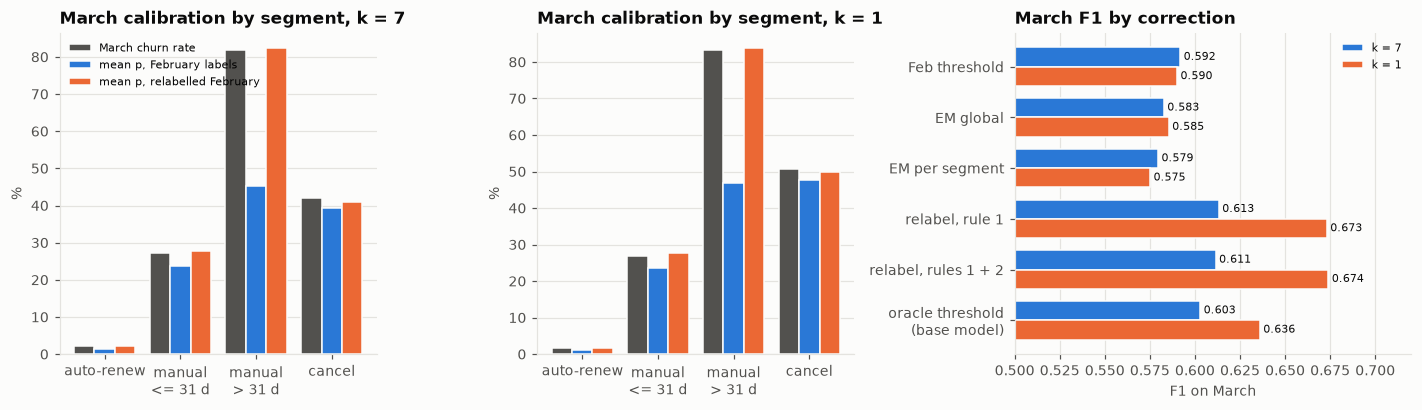

In [11]:
# calibration by segment on March: base model vs model trained on the relabelled February
cal = pd.concat({f"k={k}": (data[k].filter(pl.col("split") == "march").group_by("segment")
                            .agg(n=pl.len(), churn=pl.col("is_churn").mean(), base=pl.col("p").mean(),
                                 rule1=pl.col("p_y_rule1").mean(), rules12=pl.col("p_y_rule12").mean())
                            .to_pandas().set_index("segment").loc[SEG_ORDER]) for k in KS})
cal.columns = ["n", "March churn rate", "mean p, base", "mean p, rule 1", "mean p, rules 1 + 2"]
display(cal)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.25]})
x, w = np.arange(len(SEG_ORDER)), 0.27
labels = ["auto-renew", "manual\n<= 31 d", "manual\n> 31 d", "cancel"]
for ax, k in zip(axes[:2], KS):
    c = cal.loc[f"k={k}"]
    ax.bar(x - w, c["March churn rate"] * 100, w, color=C.COLORS["base"], label="March churn rate", edgecolor=C.COLORS["surface"])
    ax.bar(x, c["mean p, base"] * 100, w, color=C.COLORS["stay"], label="mean p, February labels", edgecolor=C.COLORS["surface"])
    ax.bar(x + w, c["mean p, rules 1 + 2"] * 100, w, color=C.COLORS["churn"], label="mean p, relabelled February", edgecolor=C.COLORS["surface"])
    ax.set_xticks(x, labels); ax.set_ylabel("%"); ax.set_title(f"March calibration by segment, k = {k}", loc="left")
axes[0].legend(frameon=False, fontsize=7)
names = ["February threshold", "EM prior shift, global", "EM prior shift, per segment", "relabelled February, rule 1",
         "relabelled February, rules 1 + 2", "oracle threshold, base model (March labels)"]
short = ["Feb threshold", "EM global", "EM per segment", "relabel, rule 1", "relabel, rules 1 + 2", "oracle threshold\n(base model)"]
ax, yy = axes[2], np.arange(len(names))
for j, (k, color) in enumerate(zip(KS, (C.COLORS["stay"], C.COLORS["churn"]))):
    vals = [pol.loc[(k, n), "f1"] for n in names]
    ax.barh(yy + (j - 0.5) * 0.38, vals, 0.38, color=color, label=f"k = {k}", edgecolor=C.COLORS["surface"])
    for yi, v in zip(yy + (j - 0.5) * 0.38, vals):
        ax.text(v + 0.002, yi, f"{v:.3f}", va="center", fontsize=7, color=C.COLORS["text"])
ax.set_yticks(yy, short); ax.invert_yaxis(); ax.set_xlim(0.5, 0.72); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 on March"); ax.set_title("March F1 by correction", loc="left"); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); C.save_fig(fig, "12_march_shift"); plt.show()

### 5.1 Does the same hold for the calendar cutoff? (notebook 09 / w1 setting)

The label mismatch is a property of the two label files, so it should also affect the model of notebook 09: whole
cohort (including the 11 % whose expiry is not in the label month), one fixed cutoff (2017-01-31 / 2017-02-28) and
`expiry_month` instead of `days_to_expire`. The cell below rebuilds that model and trains it on four targets:

| target | February label switched to churn when ... |
|---|---|
| official | nothing |
| rules 1 + 2, in scope | rule 1 or rule 2, only for customers whose expiry is in the label month (as above) |
| rules 1 + 2, everyone | same, and for the other customers the window is the 31 days after the cutoff |
| rules 1 + 2 + 3 | also every customer already paid beyond the next month at the cutoff (`expiry_month = later`) |

Rule 3 comes from the first table below: customers prepaid beyond the next month churn 40 % in February and 90 % in
March, and those among them who make a normal paid renewal after the cutoff are 0.4 % churn in February and 86 %
in March. It is the same idea as rule 1 (a subscription that runs far past the label month is churn in `train_v2`),
but it was only looked at here, so it is reported as exploratory.

In [12]:
CAT9 = ["state", "expiry_month", "plan_band", "price_level", "price_type", "pm_group", "via", "profile_state", "age_band"]
NUM9 = [c for c in NUM if c != "days_to_expire"]
F9 = CAT9 + NUM9

def month_expiry(df, cutoff):
    first_label = (pd.Timestamp(cutoff) + pd.Timedelta(days=1)).date()
    nxt = (pd.Timestamp(first_label) + pd.offsets.MonthBegin(1)).date()
    after = (pd.Timestamp(nxt) + pd.offsets.MonthBegin(1)).date()
    e = pl.col("last_expire")
    return df.with_columns(expiry_month=pl.when(pl.col("expiry_state") == "no txn").then(pl.lit("no txn"))
        .when(e.is_null()).then(pl.lit("unknown")).when(e <= pl.lit(cutoff)).then(pl.lit("lapsed"))
        .when(e < pl.lit(nxt)).then(pl.lit("label month")).when(e < pl.lit(after)).then(pl.lit("next month"))
        .otherwise(pl.lit("later")))

def calendar_table(name, users, ref, keep_methods):
    C.set_cutoff(ref)
    base = users.select("msno", "is_churn")
    txn = C.clean_transactions(base)
    df = (month_expiry(C.state_block(C.subscription_state(txn, base), keep_methods=keep_methods), ref)
          .join(C.history_block(txn, base), on="msno").join(C.listening_block(base), on="msno")
          .join(C.member_block(base), on="msno").with_columns(payer_days=pl.col("payer_days").clip(upper_bound=730)))
    del txn; gc.collect()
    C.set_cutoff(TXN_END)
    post = C.clean_transactions(base).filter(pl.col("td") > pl.lit(ref))
    C.set_cutoff(FEB_REF)
    # window start: the expiry when it falls in the label month, otherwise the day after the cutoff
    a = df.select("msno", anchor=pl.when(pl.col("expiry_month") == "label month").then(pl.col("last_expire"))
                  .otherwise(pl.lit(ref + timedelta(days=1))))
    t = post.join(a, on="msno")
    in_window = (pl.col("td") >= pl.col("anchor")) & (pl.col("td") <= pl.col("anchor") + pl.duration(days=30))
    standard = (pl.col("payment_plan_days") <= 31) & (pl.col("actual_amount_paid") > 0)
    w = t.filter((pl.col("is_cancel") == 0) & in_window).group_by("msno").agg(
        n_window=pl.len(), any_standard=standard.any(), any_long=(pl.col("payment_plan_days") > 31).any())
    u = a.with_columns(as_of=pl.col("anchor") + pl.duration(days=30))
    s = C.subscription_state(C.filter_as_of(post, u), u).select(
        "msno", final_state="state", final_ext=(pl.col("last_expire") - pl.col("anchor")).dt.total_days())
    return (df.join(users.select("msno", "split"), on="msno").join(w, on="msno", how="left").join(s, on="msno", how="left")
            .with_columns(
                cohort=pl.lit(name),
                long_only=(pl.col("n_window").is_not_null() & ~pl.col("any_standard") & pl.col("any_long")).fill_null(False),
                renew_cancel=(pl.col("n_window").is_not_null() & (pl.col("final_state") == "cancel") & (pl.col("final_ext") <= 25)).fill_null(False),
                renewal=pl.when(pl.col("n_window").is_null()).then(pl.lit("4 no payment seen in the window"))
                .when(pl.col("any_standard")).then(pl.lit("1 paid renewal, plan <= 31 d"))
                .when(pl.col("any_long")).then(pl.lit("2 renewal only with a plan > 31 d"))
                .otherwise(pl.lit("3 only free renewals, plan <= 31 d")))
            .select(["msno", "is_churn", "split", "cohort", "long_only", "renew_cancel", "renewal"] + F9))

cal_path = C.CACHE_DIR / "12_calendar.parquet"
if not cal_path.exists():
    cohort = C.load_cohort()
    mar_cohort = pl.read_parquet(C.PARQUET_DIR / "train_v2.parquet", columns=["msno", "is_churn"]).with_columns(split=pl.lit("march"))
    fit_users = cohort.filter(pl.col("split") == "fit").select("msno", "is_churn")
    C.set_cutoff(FEB_REF)
    counts = C.subscription_state(C.clean_transactions(fit_users), fit_users).group_by("last_payment_method_id").len()
    keep_m = counts.filter((pl.col("len") >= 1000) & pl.col("last_payment_method_id").is_not_null())["last_payment_method_id"].to_list()
    pl.concat([calendar_table("feb", cohort.select("msno", "is_churn", "split"), FEB_REF, keep_m),
               calendar_table("mar", mar_cohort, MAR_REF, keep_m)], how="vertical_relaxed").write_parquet(cal_path)
    C.set_cutoff(FEB_REF)
cal_d = pl.read_parquet(cal_path)

EXP_ORDER = ["label month", "next month", "lapsed", "later", "no txn"]
t = cal_d.group_by("expiry_month", "cohort").agg(n=pl.len(), churn=pl.col("is_churn").mean()).to_pandas()
display(t.pivot_table(index="expiry_month", columns="cohort", values=["n", "churn"]).loc[EXP_ORDER])
t = (cal_d.filter(pl.col("expiry_month") != "label month").group_by("expiry_month", "renewal", "cohort")
     .agg(n=pl.len(), churn=pl.col("is_churn").mean()).filter(pl.col("n") >= 100).to_pandas())
t.pivot_table(index=["expiry_month", "renewal"], columns="cohort", values=["n", "churn"])

churn                   n             
cohort          feb    mar          feb          mar
expiry_month                                        
label month  0.0556 0.0729 883,631.0000 865,793.0000
next month   0.0400 0.0897  85,485.0000  77,433.0000
lapsed       0.5082 0.4973  14,140.0000  16,993.0000
later        0.4022 0.9043   7,574.0000   8,214.0000
no txn       0.3155 0.5468   2,095.0000   2,524.0000

churn                  n            
cohort                                             feb    mar         feb         mar
expiry_month renewal                                                                 
lapsed       1 paid renewal, plan <= 31 d       0.0430 0.1475  7,065.0000  9,929.0000
             2 renewal only with a plan > 31 d  0.4860 0.9496    321.0000    476.0000
             4 no payment seen in the window    0.9966 0.9959  6,709.0000  6,525.0000
later        1 paid renewal, plan <= 31 d       0.0042 0.8568  4,474.0000  5,481.0000
             3 only free renewals, plan <= 31 d 0.9926    NaN    272.0000         NaN
             4 no payment seen in the window    0.9824 0.9996  2,781.0000  2,706.0000
next month   1 paid renewal, plan <= 31 d       0.0005 0.0415 81,035.0000 72,821.0000
             4 no payment seen in the window    0.7713 0.8480  4,325.0000  4,520.0000
no txn       1 paid renewal, plan <= 31 d       0.1023 0.2123  1,192.0000  1,347.0000
             2 renewal only with a plan > 31 d  0.4562 0.9296    651.0000    980.0000
             3 only free renewals, plan <= 31 d 0.9615 0.9255    234.0000    188.0000

In [13]:
in_scope, yb = pl.col("expiry_month") == "label month", pl.col("is_churn").cast(pl.Boolean)
flip = pl.col("long_only") | pl.col("renew_cancel")
TARGETS = {"official": "is_churn", "rules 1 + 2, in scope": "y_scope", "rules 1 + 2, everyone": "y_all", "rules 1 + 2 + 3": "y_all3"}
cal_d = cal_d.with_columns(y_scope=(yb | (in_scope & flip)).cast(pl.Int8), y_all=(yb | flip).cast(pl.Int8),
                           y_all3=(yb | flip | (pl.col("expiry_month") == "later")).cast(pl.Int8))
LEVELS9 = {c: sorted(v for v in cal_d.filter(pl.col("cohort") == "feb")[c].unique().to_list() if v is not None) for c in CAT9}
def to_X9(df):
    p = df.select(F9).to_pandas()
    for c in CAT9:
        codes = pd.Categorical(p[c].astype(object), categories=LEVELS9[c]).codes.astype(float)
        codes[codes < 0] = np.nan
        p[c] = codes
    return p.astype(float)

fit9, stop9, tune9, mar9 = (cal_d.filter(pl.col("split") == s) for s in ("fit", "stop", "tune", "march"))
Xf, Xs, Xt, Xm = map(to_X9, (fit9, stop9, tune9, mar9))
y9, rows, p9, flag9 = mar9["is_churn"].to_numpy(), [], {}, {}
for name, target in TARGETS.items():
    m = XGBClassifier(**PARAMS, feature_types=["c" if c in CAT9 else "q" for c in F9])
    m.fit(Xf, fit9[target].to_numpy(), eval_set=[(Xs, stop9[target].to_numpy())], verbose=False)
    thr, _ = best_threshold(tune9[target].to_numpy(), m.predict_proba(Xt)[:, 1])
    p9[name] = m.predict_proba(Xm)[:, 1]
    flag9[name] = p9[name] >= thr
    pr, rc, f1 = prf(y9, flag9[name])
    rows.append({"training target": name, "Feb churn rate": cal_d.filter(pl.col("cohort") == "feb")[target].mean(),
                 "March mean p": p9[name].mean(), "March churn rate": y9.mean(), "avg_precision": average_precision_score(y9, p9[name]),
                 "precision": pr, "recall": rc, "f1 at Feb threshold": f1, "f1 at best March threshold": best_threshold(y9, p9[name])[1]})
cal_res = pd.DataFrame(rows).set_index("training target")
for name in list(TARGETS)[1:]:
    m_, lo, hi = boot_f1_diff(y9, flag9["official"], flag9[name])
    cal_res.loc[name, ["d_f1 vs official", "ci_95_low", "ci_95_high"]] = m_, lo, hi
display(cal_res)
t = (mar9.with_columns(**{f"p: {k}": pl.Series(v) for k, v in p9.items()}).group_by("expiry_month")
     .agg(n=pl.len(), churn=pl.col("is_churn").mean(), **{f"p: {k}": pl.col(f"p: {k}").mean() for k in p9})
     .to_pandas().set_index("expiry_month").loc[EXP_ORDER])
t

,Feb churn rate,March mean p,March churn rate,avg_precision,precision,recall,f1 at Feb threshold,f1 at best March threshold,d_f1 vs official,ci_95_low,ci_95_high
training target,,,,,,,,,,,
official,0.0639,0.0637,0.0899,0.6009,0.6429,0.5357,0.5844,0.5853,NaN,NaN,NaN
"rules 1 + 2, in scope",0.0808,0.0798,0.0899,0.6251,0.6541,0.5406,0.5919,0.5920,0.0075,0.0065,0.0084
"rules 1 + 2, everyone",0.0814,0.0812,0.0899,0.6273,0.6567,0.5392,0.5922,0.5923,0.0078,0.0069,0.0088
rules 1 + 2 + 3,0.0859,0.0866,0.0899,0.6609,0.7125,0.5618,0.6282,0.6298,0.0438,0.0421,0.0456


,n,churn,p: official,"p: rules 1 + 2, in scope","p: rules 1 + 2, everyone",p: rules 1 + 2 + 3
expiry_month,,,,,,
label month,865793,0.0729,0.0546,0.0728,0.0728,0.0727
next month,77433,0.0897,0.0426,0.0419,0.0433,0.0432
lapsed,16993,0.4973,0.4540,0.4510,0.4842,0.4822
later,8214,0.9043,0.3308,0.3307,0.3342,0.9990
no txn,2524,0.5468,0.3394,0.3428,0.5713,0.5718


**Yes: the calendar model has the same problem, and the same fix helps.**
- With the official February labels the calendar model predicts 6.4 % on a March cohort that churns 9.0 %.
- Rules 1 + 2 bring the customers who expire in the label month to the right level (7.3 % predicted, 7.3 % real)
  and raise AP from 0.601 to 0.627 and F1 from 0.584 to 0.592. The F1 gain is smaller than in the per-cycle model
  because here the 11 % out of scope, which hold 28 % of the March churners, are still mislabelled.
- Rule 3 fixes the prepaid group (33 % predicted vs 90 % real before, 100 % after) and takes F1 to 0.628 and AP to
  0.661.
- Customers who expire in the *next* month are still under-predicted (4.3 % vs 9.0 %): among them, a normal paid
  renewal is 0.05 % churn in February and 4 % in March. That part of the `train_v2` rule is not identified here.

So the relabelling is needed for any model trained on `train` and evaluated on `train_v2`, whatever the cutoff. The
per-cycle population (expiry in the label month) is the one where the two rules found here account for the whole
difference.

## 6. Conclusion

**The February → March shift is a change in the label definition, not a prior shift, not covariate shift and not
customer behaviour.** `train` (February) and `train_v2` (March) label the same renewal behaviour differently.

**1. Where the under-prediction sits (section 2).** Three segments, each calibrated in February:

| segment | share of customers | churn Feb → Mar | mean p in March | share of the deficit |
|---|---|---|---|---|
| manual, plan > 31 days | 2.5 % | 44–47 % → 82–83 % | 45–47 % | 48–50 % |
| auto-renew | 86 % | 1.2–1.7 % → 1.8–2.2 % | 1.1–1.5 % | 29–31 % |
| manual, plan ≤ 31 days | 10 % | 25 % → 27 % | 23.5 % | 17–18 % |
| cancel / cancel + payment | 2 % | 37–46 % → 42–51 % | 39–48 % | 2–3 % |

Payment method, expiry day, listening activity, tenure and number of payments only re-express these segments.

**2. Covariates or concept (section 3).** Concept, in every segment. The March features alone predict slightly
less churn than February (covariate effect between −2 and +2 points), and the churn rate given the features rises
(+0.6 points for auto-renewers, +3.5 for manual 30-day payers, +37 for manual long-plan customers). The only strong
feature differences are calendar artefacts in `payer_days`, `n_payments` and `days_to_expire`, which do not move
the predictions.

**3. The cause (section 4).** Customers renew at the same pace after the expiry in both months. What changes is
how a renewal is labelled:
- a renewal with a plan longer than 31 days: 2 % churn in February, **97 % churn in March** (9,700 March
  churners, 15 % of all);
- a renewal followed by a cancellation: 48 % churn in February, 96 % in March.

Applying these two rules to the February cohort from its own transactions moves its churn rate from 5.6 % to
7.4 % (March: 7.3 %) and puts every segment on its March rate.

**4. Corrections (section 5), March F1 at the threshold chosen on February:**

| correction | k = 7 | k = 1 | needs |
|---|---|---|---|
| February threshold (baseline) | 0.59 | 0.58–0.59 | — |
| EM prior shift, global | −0.009 | −0.005 | March scores |
| EM prior shift, per segment | −0.012 | −0.015 | March scores |
| same flagged share | +0.002 | +0.002 | March scores |
| relabelled February, rule 1 | **+0.021 (0.613)** | **+0.083 (0.673)** | February transactions + the March rule |
| relabelled February, rules 1 + 2 | +0.020 (0.611) | +0.084 (0.674) | same |
| oracle threshold on the base model | +0.011 (0.603) | +0.046 (0.636) | March labels |

- **Label-free corrections do not work.** EM estimates the March rate at 5.0–5.3 %, *below* the training rate,
  and lowers F1. The gain reported in notebook 10 (+0.004 to +0.011) came from the "common customers" filter:
  dropping the 15 % of March customers not eligible at k = 28 removes low-score customers and pushes the estimate
  up to 6.0–6.1 %. On the full eligible population the correction is harmful. No method that keeps the February
  labels can work, because the customers whose label changed cannot be told apart at `as_of`.
- **Training on February labels rebuilt with the March rule fixes it.** March AP rises from 0.618 to 0.661
  (k = 7) and from 0.682 to 0.730 (k = 1). F1 goes above the old "oracle threshold" ceiling, because the gain is in
  the ranking and not only in the cut-off. The model is calibrated on March in every segment, and the February
  threshold lands within 0.002 F1 of the best March threshold, so **no recalibration or prior correction is
  needed afterwards**.
- Rule 1 gives the whole F1 gain. Rule 2 does not change F1 (a cancellation after the renewal cannot be predicted
  before the expiry) but it calibrates the auto-renewers (2.1 % predicted vs 2.2 % real at k = 7).
- With the label fixed, F1 on March grows with shorter lead time, as on February: 0.61 at k = 7 and 0.67 at k = 1.
  The plateau of notebook 10 was produced by the label mismatch.

**Caveat on the protocol.** The relabelled models are fitted, early-stopped and thresholded on February only, and
the relabelled target is computed from February transactions (a closed month). But the rule itself was found by
auditing March labels (section 4.2). It is a statement about what the target means, with 97 % purity on 10,000
customers, not a tuned parameter, so the risk of an optimistic estimate is small. Still, the +0.02 / +0.08 is not
a blind estimate in the strict sense. The alternative that needs no March label is to get the definition of the
`train_v2` label from its source and build the training target with it.

**Recommendation.**
1. Treat `train` and `train_v2` as two label definitions. For any model evaluated on March, build the February
   training target with the March rule (rules 1 + 2) from the transactions; keep the official February label only
   for February reporting.
2. Drop the EM prior correction and the "recalibrate monthly" item of notebook 10: with a consistent label the
   February threshold transfers.
3. The calendar model of notebook 09 / w1 has the same problem (section 5.1): rules 1 + 2 raise its March F1 from
   0.584 to 0.592 and AP from 0.601 to 0.627. Its out-of-scope customers need more of the `train_v2` rule: treating
   customers prepaid beyond the next month as churn (exploratory rule 3) takes F1 to 0.628, and the customers who
   expire in the next month are still under-predicted.

In [14]:
C.write_decisions("12", "Why the per-cycle model under-predicts March", [
    {"finding": "The March shortfall sits in three segments that are calibrated in February: manual payers on plans > 31 d (2.5 % of customers, ~50 % of the deficit, churn 44-47 % -> 82-83 %, mean p 45-47 %), auto-renewers (~30 %, 1.2-1.7 % -> 1.8-2.2 %) and manual 30-day payers (~17 %, 25 % -> 27 %)",
     "decision": "Report calibration by these four state x plan-length segments whenever a model is moved to another month", "kind": "no action"},
    {"finding": "Not covariate shift: March features alone predict slightly less churn (covariate effect -2..+2 points per segment); the churn rate given the features rises (+0.6 / +3.5 / +37 points). The only strong feature differences are calendar artefacts (payer_days, n_payments, days_to_expire) that do not move predictions",
     "decision": "No feature change and no covariate reweighting", "kind": "no action"},
    {"finding": "The label definition differs between train (Feb) and train_v2 (Mar) while renewal behaviour is identical: a renewal with a plan > 31 d in the 30-day window is 2 % churn in Feb and 97 % in Mar (9,700 March churners); a renewal followed by a cancellation is 48 % vs 96 %. Applying both rules to February moves its churn rate 5.6 % -> 7.4 % (March 7.3 %), every segment on its March rate",
     "decision": "For models evaluated on March, rebuild the February training target from transactions with the March rule (official label OR long-plan-only renewal OR renew-then-cancel). Rule found by auditing March labels: needs sign-off, or confirmation of the train_v2 definition from its source", "kind": "open"},
    {"finding": "Trained on the relabelled February target (same features, settings, protocol), March F1 at the February threshold goes 0.592 -> 0.613 (k=7) and 0.590 -> 0.674 (k=1), AP 0.618 -> 0.661 and 0.682 -> 0.730; the February threshold is within 0.002 F1 of the best March threshold and every segment is calibrated",
     "decision": "No threshold transfer or recalibration step is needed once the label is consistent; the March F1 plateau of notebook 10 was the label mismatch", "kind": "transformation"},
    {"finding": "Label-free corrections fail on the full eligible population: EM prior shift estimates 5.0-5.3 % (below the training rate) and costs -0.009 / -0.005 F1, per-segment EM -0.012 / -0.015. The gain reported in notebook 10 came from the common-customers filter",
     "decision": "Drop the EM prior correction and the monthly recalibration item (supersedes the last two rows of section 10)", "kind": "drop"},
    {"finding": "The calendar-cutoff model (whole cohort, notebook 09 setting) has the same mismatch: 6.4 % predicted vs 9.0 % real in March. Rules 1 + 2 give F1 0.584 -> 0.592 and AP 0.601 -> 0.627; also labelling customers prepaid beyond the next month as churn (40 % churn in Feb, 90 % in Mar) gives F1 0.628, AP 0.661. Customers expiring in the next month stay under-predicted (4.3 % vs 9.0 %)",
     "decision": "The relabelled target is needed for any model trained on train and evaluated on train_v2, not only per-cycle; the rule for customers whose expiry is outside the label month is only partly identified (rule 3 is exploratory)", "kind": "open"},
])

,finding,decision,kind
0,The March shortfall sits in three segments tha...,Report calibration by these four state x plan-...,no action
1,Not covariate shift: March features alone pred...,No feature change and no covariate reweighting,no action
2,The label definition differs between train (Fe...,"For models evaluated on March, rebuild the Feb...",open
3,Trained on the relabelled February target (sam...,No threshold transfer or recalibration step is...,transformation
4,Label-free corrections fail on the full eligib...,Drop the EM prior correction and the monthly r...,drop
5,"The calendar-cutoff model (whole cohort, noteb...",The relabelled target is needed for any model ...,open
